# Lab 7 - 28.8.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    1. Generate the models to classify the Thyroid disease for the given dataset
       “allrep-thyroid”. Select the suitable features. Feature details and
       Target class labels are given below. Use train and test data to analyze
       the performance of the data and visualize the results. Use minimum 3
       models to evaluate the performance. (SVM has to be included).

       Class labels: replacement therapy, under replacement, over replacement,
       negative

       Features: age (continuous), sex, on thyroxine (f), query on thyroxine
       (f), on antithyroid medication (f), sick (f), pregnant (f), thyroid
       surgery (f), I131 treatment (f), query hypothyroid (f), query
       hyperthyroid (f), lithium (f), goitre (f), tumor (f), hypopituitary (f),
       psych (f), TSH measured (f), TSH (continuous), T3 measured (f), T3
       (continuous), TT4 measured (f), TT4 (continuous), T4U measured (f), T4U
       (continuous), FTI measured (f), FTI (continuous).

    2. Generate the model to cluster the data for the given dataset
       “gas-turbine” using K-Means clustering. Use the following input
       features - 'CO', 'NOx', 'TIT', 'GTEP'. 2013, 2014 - training, 2015 -
       test data. Analyze the performance of the data and visualize the
       results.

### 1.

### SVM, Random Forest & Logistic Regression - Thyroid disease classification

#### Load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay, silhouette_score)

In [2]:
thyroid_cols = ['age', 'sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_med',
                'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment', 'query_hypothyroid',
                'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych',
                'TSH_measured', 'TSH', 'T3_measured', 'T3', 'TT4_measured', 'TT4',
                'T4U_measured', 'T4U', 'FTI_measured', 'FTI', 'class_id']

thyroid_train = pd.read_csv('Lab 7- 28.8.26/allrep-thyroid/allrep.train', header=None,
                             names=thyroid_cols, na_values='?')
thyroid_test = pd.read_csv('Lab 7- 28.8.26/allrep-thyroid/allrep.test', header=None,
                            names=thyroid_cols, na_values='?')

# The class label and a record id are packed together as "label.|id"
for d in (thyroid_train, thyroid_test):
    d['class'] = d['class_id'].str.split('|').str[0].str.rstrip('.')

thyroid_train.head()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_med,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,class_id,class
0,41.0,F,f,f,f,f,f,f,f,f,...,t,2.5,t,125.0,t,1.14,t,109.0,negative.|3733,negative
1,23.0,F,f,f,f,f,f,f,f,f,...,t,2.0,t,102.0,f,NaN,f,NaN,negative.|1442,negative
2,46.0,M,f,f,f,f,f,f,f,f,...,f,NaN,t,109.0,t,0.91,t,120.0,negative.|2965,negative
3,70.0,F,t,f,f,f,f,f,f,f,...,t,1.9,t,175.0,f,NaN,f,NaN,replacement therapy.|806,replacement therapy
4,70.0,F,f,f,f,f,f,f,f,f,...,t,1.2,t,61.0,t,0.87,t,70.0,negative.|2807,negative


In [3]:
thyroid_train['class'].value_counts()

class
negative               2713
underreplacement         35
replacement therapy      29
overreplacement          23
Name: count, dtype: int64

#### Select features

The `*_measured` flags only indicate whether the matching lab value is missing
(already captured by the `NaN`s below), and most of the binary history flags
(`on_thyroxine`, `goitre`, `pregnant`, etc.) are almost constant - `hypopituitary`
is `t` in just 1 of 2800 rows - so they carry little signal for this label.
The label itself (replacement therapy dosage adequacy) is driven mainly by the
hormone panel, so the selected features are the demographic fields plus the
five continuous lab measurements: age, sex, TSH, T3, TT4, T4U and FTI.

In [4]:
features_thyroid = ['age', 'sex', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']

X_train_t = thyroid_train[features_thyroid].copy()
y_train_t = thyroid_train['class']
X_test_t = thyroid_test[features_thyroid].copy()
y_test_t = thyroid_test['class']

#### Preprocessing

In [5]:
X_train_t['sex'] = X_train_t['sex'].map({'F': 0, 'M': 1})
X_test_t['sex'] = X_test_t['sex'].map({'F': 0, 'M': 1})

# Impute missing lab values using statistics learned from the training set only
imputer = SimpleImputer(strategy='median')
X_train_t_imp = pd.DataFrame(imputer.fit_transform(X_train_t), columns=features_thyroid)
X_test_t_imp = pd.DataFrame(imputer.transform(X_test_t), columns=features_thyroid)

scaler_t = StandardScaler()
X_train_t_scaled = scaler_t.fit_transform(X_train_t_imp)
X_test_t_scaled = scaler_t.transform(X_test_t_imp)

#### Train models

In [6]:
# The classes are heavily imbalanced (negative is ~97% of the data), so every
# model is trained with balanced class weights
svm_model = SVC(kernel='rbf', class_weight='balanced', random_state=1265)
svm_model.fit(X_train_t_scaled, y_train_t)

rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=1265)
rf_model.fit(X_train_t_scaled, y_train_t)

logreg_model = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=1265)
logreg_model.fit(X_train_t_scaled, y_train_t)

y_pred_svm = svm_model.predict(X_test_t_scaled)
y_pred_rf = rf_model.predict(X_test_t_scaled)
y_pred_logreg = logreg_model.predict(X_test_t_scaled)

#### Performance evaluation

In [7]:
models_thyroid = {'SVM': y_pred_svm, 'Random Forest': y_pred_rf, 'Logistic Regression': y_pred_logreg}

# With this much class imbalance, macro-F1 (unweighted average across classes) is
# a more honest performance signal than raw accuracy
thyroid_accuracies = {}
thyroid_f1_scores = {}

for name, y_pred in models_thyroid.items():
    thyroid_accuracies[name] = accuracy_score(y_test_t, y_pred)
    thyroid_f1_scores[name] = f1_score(y_test_t, y_pred, average='macro')
    print(f"--- {name} ---")
    print(f"Accuracy: {thyroid_accuracies[name]:.4f}, Macro F1: {thyroid_f1_scores[name]:.4f}")
    print(classification_report(y_test_t, y_pred, zero_division=0))
    print()

--- SVM ---
Accuracy: 0.8920, Macro F1: 0.5172
                     precision    recall  f1-score   support

           negative       1.00      0.90      0.94       935
    overreplacement       0.43      0.82      0.56        11
replacement therapy       0.16      0.56      0.24         9
   underreplacement       0.19      0.88      0.32        17

           accuracy                           0.89       972
          macro avg       0.44      0.79      0.52       972
       weighted avg       0.97      0.89      0.92       972


--- Random Forest ---
Accuracy: 0.9630, Macro F1: 0.3293
                     precision    recall  f1-score   support

           negative       0.96      1.00      0.98       935
    overreplacement       0.50      0.09      0.15        11
replacement therapy       0.50      0.11      0.18         9
   underreplacement       0.00      0.00      0.00        17

           accuracy                           0.96       972
          macro avg       0.49      

#### Visualize results

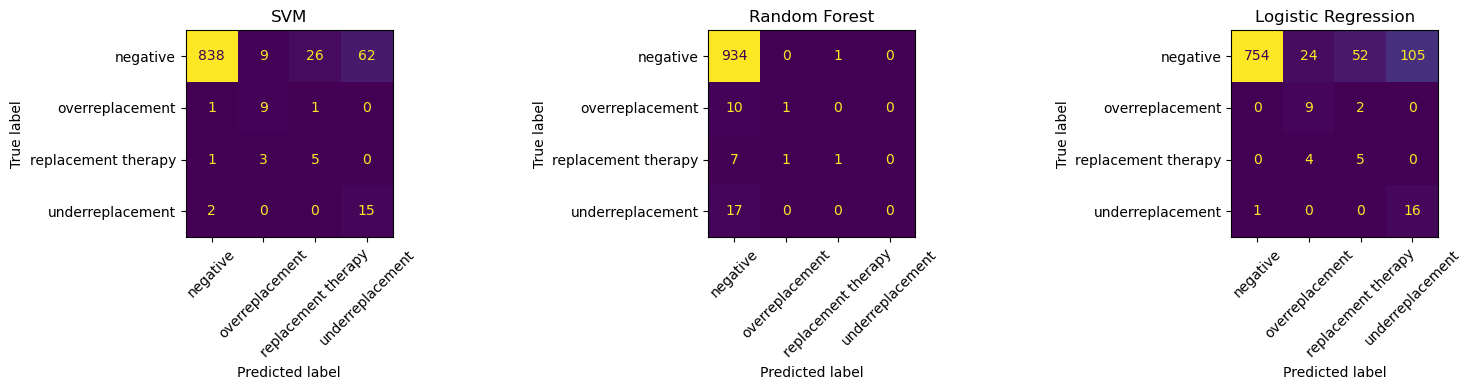

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, y_pred) in zip(axes, models_thyroid.items()):
    cm = confusion_matrix(y_test_t, y_pred, labels=svm_model.classes_)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=svm_model.classes_).plot(
        ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(name)

plt.tight_layout()
plt.show()

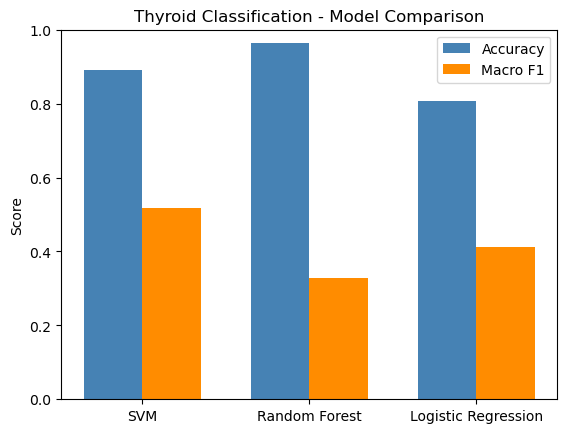

In [9]:
x_pos = np.arange(len(models_thyroid))
width = 0.35

plt.bar(x_pos - width/2, thyroid_accuracies.values(), width, label='Accuracy', color='steelblue')
plt.bar(x_pos + width/2, thyroid_f1_scores.values(), width, label='Macro F1', color='darkorange')
plt.xticks(x_pos, models_thyroid.keys())
plt.ylabel('Score')
plt.ylim(0, 1)
plt.title('Thyroid Classification - Model Comparison')
plt.legend()
plt.show()

### 2.

### K-Means Clustering - Gas turbine emissions

#### Load dataset

In [10]:
gt_2013 = pd.read_csv('Lab 7- 28.8.26/gas-turbin/gt_2013.csv')
gt_2014 = pd.read_csv('Lab 7- 28.8.26/gas-turbin/gt_2014.csv')
gt_2015 = pd.read_csv('Lab 7- 28.8.26/gas-turbin/gt_2015.csv')

gt_2013.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,9.3779,1020.1,90.262,2.3927,19.166,1043.6,541.16,110.16,10.564,9.3472,98.741
1,9.2985,1019.9,89.934,2.3732,19.119,1039.9,538.94,109.23,10.572,11.0160,104.290
2,9.1337,1019.8,89.868,2.3854,19.178,1041.0,539.47,109.62,10.543,10.7500,103.470
3,8.9715,1019.3,89.490,2.3825,19.180,1037.1,536.89,108.88,10.458,12.2870,108.810
4,9.0157,1019.1,89.099,2.4044,19.206,1043.5,541.25,110.09,10.464,9.8229,100.020


#### Select features & train:test split (2013+2014 : 2015)

In [11]:
features_gt = ['CO', 'NOX', 'TIT', 'GTEP']

X_train_gt = pd.concat([gt_2013[features_gt], gt_2014[features_gt]], ignore_index=True)
X_test_gt = gt_2015[features_gt]

print(f"Train (2013+2014): {X_train_gt.shape[0]} rows, Test (2015): {X_test_gt.shape[0]} rows")

Train (2013+2014): 14310 rows, Test (2015): 7384 rows


#### Feature scaling

In [12]:
scaler_gt = StandardScaler()
X_train_gt_scaled = scaler_gt.fit_transform(X_train_gt)
X_test_gt_scaled = scaler_gt.transform(X_test_gt)

#### Find suitable number of clusters

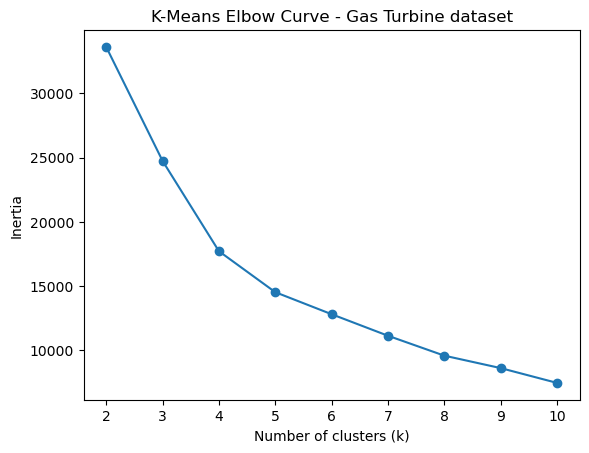

In [13]:
k_values_gt = range(2, 11)
inertias = []

for k in k_values_gt:
    km = KMeans(n_clusters=k, random_state=1265, n_init=10)
    km.fit(X_train_gt_scaled)
    inertias.append(km.inertia_)

plt.plot(k_values_gt, inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('K-Means Elbow Curve - Gas Turbine dataset')
plt.show()

In [14]:
# Elbow point: the k with the largest perpendicular distance from the line
# joining the first and last point of the inertia curve
k_arr = np.array(list(k_values_gt), dtype=float)
c_arr = np.array(inertias, dtype=float)

x = (k_arr - k_arr.min()) / (k_arr.max() - k_arr.min())
y = (c_arr - c_arr.min()) / (c_arr.max() - c_arr.min())

distances = np.abs((y[-1] - y[0]) * x - (x[-1] - x[0]) * y + x[-1] * y[0] - y[-1] * x[0])
distances /= np.sqrt((y[-1] - y[0]) ** 2 + (x[-1] - x[0]) ** 2)

best_k_gt = list(k_values_gt)[np.argmax(distances)]
print(f"Suitable number of clusters (elbow point): {best_k_gt}")

Suitable number of clusters (elbow point): 4


#### Train final model

In [15]:
kmeans_gt = KMeans(n_clusters=best_k_gt, random_state=1265, n_init=10)
train_labels_gt = kmeans_gt.fit_predict(X_train_gt_scaled)
test_labels_gt = kmeans_gt.predict(X_test_gt_scaled)

#### Performance evaluation

In [16]:
train_silhouette = silhouette_score(X_train_gt_scaled, train_labels_gt)
test_silhouette = silhouette_score(X_test_gt_scaled, test_labels_gt)

print(f"Train (2013+2014) Silhouette Score: {train_silhouette:.4f}")
print(f"Test (2015) Silhouette Score: {test_silhouette:.4f}")
print()
print("Train cluster sizes:")
print(pd.Series(train_labels_gt).value_counts().sort_index())
print()
print("Test cluster sizes:")
print(pd.Series(test_labels_gt).value_counts().sort_index())

Train (2013+2014) Silhouette Score: 0.4175
Test (2015) Silhouette Score: 0.4083

Train cluster sizes:
0    2903
1    3404
2    7337
3     666
Name: count, dtype: int64

Test cluster sizes:
0    1555
1    2593
2    2826
3     410
Name: count, dtype: int64


#### Visualize results

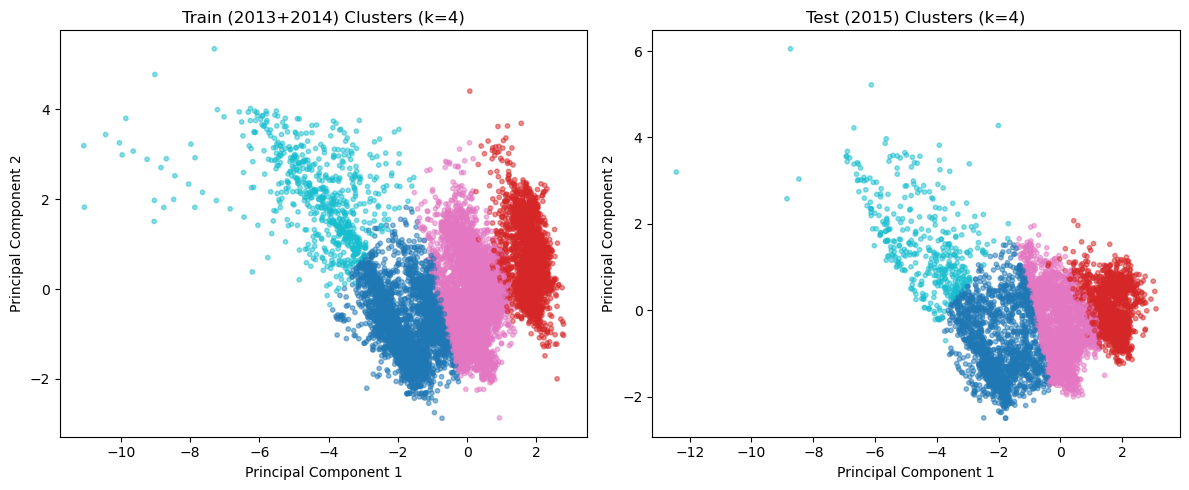

In [17]:
pca_gt = PCA(n_components=2, random_state=1265)
X_train_gt_pca = pca_gt.fit_transform(X_train_gt_scaled)
X_test_gt_pca = pca_gt.transform(X_test_gt_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_train_gt_pca[:, 0], X_train_gt_pca[:, 1], c=train_labels_gt, cmap='tab10', alpha=0.5, s=10)
axes[0].set_title(f'Train (2013+2014) Clusters (k={best_k_gt})')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

axes[1].scatter(X_test_gt_pca[:, 0], X_test_gt_pca[:, 1], c=test_labels_gt, cmap='tab10', alpha=0.5, s=10)
axes[1].set_title(f'Test (2015) Clusters (k={best_k_gt})')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

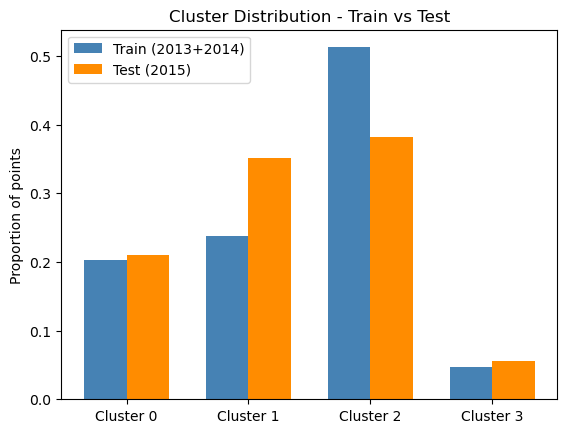

In [18]:
train_props = pd.Series(train_labels_gt).value_counts(normalize=True).sort_index()
test_props = pd.Series(test_labels_gt).value_counts(normalize=True).sort_index()

x_pos = np.arange(best_k_gt)
width = 0.35

plt.bar(x_pos - width/2, train_props.values, width, label='Train (2013+2014)', color='steelblue')
plt.bar(x_pos + width/2, test_props.reindex(range(best_k_gt), fill_value=0).values, width,
        label='Test (2015)', color='darkorange')
plt.xticks(x_pos, [f'Cluster {i}' for i in range(best_k_gt)])
plt.ylabel('Proportion of points')
plt.title('Cluster Distribution - Train vs Test')
plt.legend()
plt.show()